# Il Paradosso della Resilienza
## Identificazione di uno Scudo Trascrittomico Cerebrale contro le Infezioni Sistemiche tramite Anomaly Detection

**Pipeline completa:** Data Wrangling → Autoencoder → Feature Extraction → Visualizzazione

---
## FASE 1  Setup Data Wrangling

In [35]:
import re
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

print('Done.')
print(f'PyTorch version: {torch.__version__}')

Done.
PyTorch version: 2.5.1+cu121


In [36]:
SERIES_MATRIX = 'GSE313307_series_matrix.txt'

samples = []

with open(SERIES_MATRIX, 'r', encoding='utf-8') as f:
    for line in f:
        if line.startswith('!Sample_title'):
            # Ogni entry ha formato: "BBNXXXXXX, CTR no infection"
            entries = re.findall(r'"([^"]+)"', line)
            for entry in entries:
                parts = [p.strip() for p in entry.split(',')]
                sample_id = parts[0]                     # es. BBN00528597
                descriptor = parts[1].lower() if len(parts) > 1 else ''

                if 'ad' in descriptor:
                    disease = 'AD'
                elif 'ctr' in descriptor:
                    disease = 'CTR'
                else:
                    disease = 'UNKNOWN'

                if 'no infection' in descriptor:
                    infection = 'No'
                elif 'with infection' in descriptor or 'infection' in descriptor:
                    infection = 'Yes'
                else:
                    infection = 'UNKNOWN'

                samples.append({
                    'sample_id': sample_id,
                    'disease_status': disease,
                    'infection_status': infection,
                    'raw_label': entry
                })
            break  # Abbiamo trovato la riga che ci serve

meta_df = pd.DataFrame(samples)
print(f'Total samples: {len(meta_df)}')
print(meta_df['disease_status'].value_counts())
print(meta_df['infection_status'].value_counts())
meta_df.head(8)

Total samples: 202
disease_status
AD     113
CTR     89
Name: count, dtype: int64
infection_status
No     107
Yes     95
Name: count, dtype: int64


,sample_id,disease_status,infection_status,raw_label
0,BBN00528597,CTR,No,"BBN00528597, CTR no infection"
1,BBN2612,AD,Yes,"BBN2612, AD with infection"
2,BBN00632544,CTR,Yes,"BBN00632544, CTR with infection"
3,BBN7465,AD,No,"BBN7465, AD no infection"
4,BBN9341,AD,Yes,"BBN9341, AD with infection"
5,BBN9421,AD,Yes,"BBN9421, AD with infection"
6,BBN8960,AD,No,"BBN8960, AD no infection"
7,BBN00332849,CTR,Yes,"BBN00332849, CTR with infection"


In [37]:

controls_df = meta_df[meta_df['disease_status'] == 'CTR'].copy()

group_A = controls_df[controls_df['infection_status'] == 'No']['sample_id'].tolist()
group_B = controls_df[controls_df['infection_status'] == 'Yes']['sample_id'].tolist()

print(f'Group A CTR no infection (Baseline): {len(group_A)} samples')
print(f'Group B CTR with infection   (Target):   {len(group_B)} samples')
print(f'\nGroup A: {group_A}')
print(f'\nGroup B: {group_B}')

Group A CTR no infection (Baseline): 52 samples
Group B CTR with infection   (Target):   37 samples

Group A: ['BBN00528597', 'BBN00529874', 'BBN3442', 'BBN00632578', 'BBN8961', 'BBN24561', 'BBN9413', 'BBN00126722', 'BBN00328692', 'BBN19364', 'BBN9016', 'BBN8719', 'BBN24312', 'BBN9429', 'BBN00628893', 'BBN22226', 'BBN00130916', 'BBN3447', 'BBN19206', 'BBN00328560', 'BBN9430', 'BBN9354', 'BBN00128416', 'BBN00128793', 'BBN00529468', 'BBN00328342', 'BBN25060', 'BBN00332261', 'BBN00130147', 'BBN00629018', 'BBN00130208', 'BBN00126309', 'BBN00326947', 'BBN7623', 'BBN00328372', 'BBN4205', 'BBN00126719', 'BBN7519', 'BBN24528', 'BBN3454', 'BBN7545', 'BBN7196', 'BBN00328369', 'BBN00135156', 'BBN7422', 'BBN00329202', 'BBN9389', 'BBN19605', 'BBN00328775', 'BBN7477', 'BBN3378', 'BBN25058']

Group B: ['BBN00632544', 'BBN00332849', 'BBN19597', 'BBN00328567', 'BBN00128402', 'BBN13407', 'BBN9422', 'BBN00531442', 'BBN00532822', 'BBN4240', 'BBN00129136', 'BBN00631488', 'BBN00135381', 'BBN19608', 'BBN0052

In [38]:
print('Normalized matrix...')
df_norm = pd.read_csv('GSE313307_normalised_all_samples.csv.gz',
                      compression='gzip',
                      index_col=0)   # first column is gene ID (ENSGXXXXXXX)

print(f'Original dimension : {df_norm.shape}  (genes × samples)')
print(f'First example: {list(df_norm.columns[:5])}')

Normalized matrix...
Original dimension : (16593, 202)  (genes × samples)
First example: ['BBN00528597', 'BBN2612', 'BBN00632544', 'BBN7465', 'BBN9341']


In [39]:
all_cols = set(df_norm.columns)
group_A_valid = [s for s in group_A if s in all_cols]
group_B_valid = [s for s in group_B if s in all_cols]

missing_A = set(group_A) - all_cols
missing_B = set(group_B) - all_cols

if missing_A:
    print(f'!!  ID missing in Group A: {missing_A}')
if missing_B:
    print(f'!!  ID missing in Group B: {missing_B}')

print(f'\nGroup A valid: {len(group_A_valid)} samples')
print(f'Group B valid: {len(group_B_valid)} samples')

X_A = df_norm[group_A_valid].T  
X_B = df_norm[group_B_valid].T   

gene_names = df_norm.index.tolist()

print(f'\n Matrix Group A: {X_A.shape}  (samples x genes)')
print(f'Matrix Group B: {X_B.shape}  (samples x  genes)')


Group A valid: 52 samples
Group B valid: 37 samples

 Matrix Group A: (52, 16593)  (samples x genes)
Matrix Group B: (37, 16593)  (samples x  genes)


In [40]:
scaler = StandardScaler()
X_A_scaled = scaler.fit_transform(X_A.values)
X_B_scaled = scaler.transform(X_B.values)

print('Standardization done.')
print(f'X_A_scaled shape: {X_A_scaled.shape}')
print(f'X_B_scaled shape: {X_B_scaled.shape}')

Standardization done.
X_A_scaled shape: (52, 16593)
X_B_scaled shape: (37, 16593)


---
##  Autoencoder x Anomaly Detection

In [41]:
class GeneAutoencoder(nn.Module):
    """Symmetric autoencoder for gene expression data.

    Architecture: Input → 512 → 128 → 32 (bottleneck) → 128 → 512 → Output
    The encoder compresses the transcriptome into a compact latent representation.
    The decoder attempts to reconstruct it. The reconstruction error measures anomaly.
    """
    def __init__(self, input_dim: int, latent_dim: int = 32):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(512, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Linear(128, latent_dim),
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Linear(128, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(512, input_dim)
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)

    def encode(self, x):
        return self.encoder(x)


INPUT_DIM   = X_A_scaled.shape[1] 
LATENT_DIM  = 32
EPOCHS      = 150
BATCH_SIZE  = max(4, len(group_A_valid) // 2)   # 
LR          = 1e-3

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
print(f'Input  dim (genes): {INPUT_DIM:,}')
print(f'Batch size: {BATCH_SIZE}')

model = GeneAutoencoder(INPUT_DIM, LATENT_DIM).to(device)
print(f'\nParam: {sum(p.numel() for p in model.parameters()):,}')

Device: cuda
Input  dim (genes): 16,593
Batch size: 26

Param: 17,150,961


In [42]:
X_A_tensor = torch.FloatTensor(X_A_scaled).to(device)
dataset_A  = TensorDataset(X_A_tensor, X_A_tensor)
loader_A   = DataLoader(dataset_A, batch_size=BATCH_SIZE, shuffle=True)

optimizer  = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-5)
scheduler  = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
criterion  = nn.MSELoss(reduction='mean')

train_losses = []

model.train()
for epoch in range(EPOCHS):
    epoch_loss = 0.0
    for xb, _ in loader_A:
        optimizer.zero_grad()
        recon = model(xb)
        loss  = criterion(recon, xb)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    scheduler.step()
    train_losses.append(epoch_loss / len(loader_A))

    if (epoch + 1) % 25 == 0:
        print(f'Epoch [{epoch+1:>3}/{EPOCHS}]  Loss: {train_losses[-1]:.6f}')

print('\nTraining complete!')

Epoch [ 25/150]  Loss: 0.405696
Epoch [ 50/150]  Loss: 0.224744
Epoch [ 75/150]  Loss: 0.173425
Epoch [100/150]  Loss: 0.139015
Epoch [125/150]  Loss: 0.126096
Epoch [150/150]  Loss: 0.117946

Training complete!


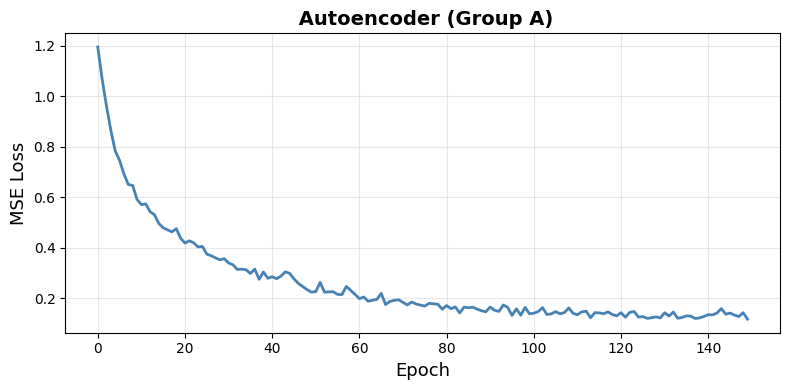

In [43]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(train_losses, color='steelblue', lw=2)
ax.set_xlabel('Epoch', fontsize=13)
ax.set_ylabel('MSE Loss', fontsize=13)
ax.set_title(' Autoencoder (Group A)', fontsize=14, fontweight='bold')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('fig_training_loss.png', dpi=150)
plt.show()

In [44]:
model.eval()

X_B_tensor = torch.FloatTensor(X_B_scaled).to(device)
X_A_tensor_eval = torch.FloatTensor(X_A_scaled).to(device)

with torch.no_grad():
    recon_A = model(X_A_tensor_eval).cpu().numpy()
    recon_B = model(X_B_tensor).cpu().numpy()

rec_error_A = np.mean((X_A_scaled - recon_A) ** 2, axis=1)
rec_error_B = np.mean((X_B_scaled - recon_B) ** 2, axis=1)

print('Riconstruction riconstruction Group A (Healty baseline):')
print(f'  Mean: {rec_error_A.mean():.4f}  |  Std: {rec_error_A.std():.4f}')
print(f'\n Riconstruction error Group B (CTR w infection):')
print(f'  Mean: {rec_error_B.mean():.4f}  |  Std: {rec_error_B.std():.4f}')

# Anomaly score per paziente in Group B
anomaly_scores = pd.Series(rec_error_B, index=group_B_valid, name='anomaly_score')
print(f'\nAnomaly score x patient (Group B):')
print(anomaly_scores.sort_values(ascending=False))

Riconstruction riconstruction Group A (Healty baseline):
  Mean: 0.0587  |  Std: 0.0439

 Riconstruction error Group B (CTR w infection):
  Mean: 0.7795  |  Std: 0.6615

Anomaly score x patient (Group B):
BBN19597       4.537393
BBN00130047    1.268050
BBN24337       1.147713
BBN00530812    1.043739
BBN13407       1.042449
BBN19603       0.901476
BBN24325       0.868485
BBN19207       0.857787
BBN00128799    0.814276
BBN9329        0.800174
BBN14416       0.783070
BBN9423        0.775198
BBN00126493    0.768045
BBN00333724    0.754765
BBN00329753    0.745590
BBN00529822    0.736595
BBN00135381    0.719174
BBN00631488    0.712324
BBN00332243    0.611891
BBN00128402    0.583105
BBN9359        0.579260
BBN4240        0.553176
BBN00735762    0.546530
BBN9408        0.529643
BBN00328567    0.521088
BBN26009       0.515146
BBN00532822    0.511955
BBN19608       0.506076
BBN8770        0.503892
BBN00129136    0.497461
BBN00531442    0.489275
BBN00632544    0.484729
BBN00332849    0.474558
BBN

---
## Resistence shield

In [45]:

# Errore x gene (shape: n_genes)
gene_error_B = np.mean(np.abs(X_B_scaled - recon_B), axis=0)
gene_error_A = np.mean(np.abs(X_A_scaled - recon_A), axis=0)

gene_delta = gene_error_B - gene_error_A

gene_scores = pd.DataFrame({
    'gene':       gene_names,
    'error_B':    gene_error_B,
    'error_A':    gene_error_A,
    'delta':      gene_delta        #
}).sort_values('delta', ascending=False).reset_index(drop=True)

print('Top 20 geni con maggiore anomalia specifica per infezione:')
print(gene_scores.head(20).to_string(index=False))

Top 20 geni con maggiore anomalia specifica per infezione:
           gene  error_B  error_A    delta
ENSG00000285612 1.531558 0.292193 1.239365
ENSG00000166889 1.308745 0.163361 1.145384
ENSG00000288534 1.408075 0.272279 1.135796
ENSG00000127252 1.436877 0.319047 1.117830
ENSG00000237945 1.354755 0.240563 1.114192
ENSG00000145861 1.329355 0.235088 1.094267
ENSG00000069535 1.268220 0.186998 1.081223
ENSG00000205740 1.296238 0.218184 1.078055
ENSG00000234177 1.312279 0.242006 1.070273
ENSG00000073169 1.227059 0.168948 1.058111
ENSG00000230074 1.324181 0.274246 1.049936
ENSG00000182253 1.177930 0.128579 1.049350
ENSG00000089505 1.289812 0.250255 1.039557
ENSG00000227252 1.196578 0.170000 1.026578
ENSG00000256525 1.206482 0.184114 1.022368
ENSG00000272667 1.254336 0.244046 1.010291
ENSG00000029639 1.196527 0.189494 1.007033
ENSG00000180479 1.255269 0.249056 1.006213
ENSG00000261094 1.240083 0.234338 1.005744
ENSG00000130449 1.147124 0.148811 0.998313


In [46]:
TOP_N = 50

top_genes_50  = gene_scores.head(50)['gene'].tolist()
top_genes_100 = gene_scores.head(100)['gene'].tolist()

with open('top50_resilience_genes.txt', 'w') as f:
    f.write('\n'.join(top_genes_50))

with open('top100_resilience_genes.txt', 'w') as f:
    f.write('\n'.join(top_genes_100))

gene_scores.to_csv('gene_anomaly_scores.csv', index=False)

print(f'\nTrascriptomic signatur x resilience Top {TOP_N} genes:')
print(top_genes_50)
print(f'\nsaved: top50_resilience_genes.txt, top100_resilience_genes.txt, gene_anomaly_scores.csv')


Trascriptomic signatur x resilience Top 50 genes:
['ENSG00000285612', 'ENSG00000166889', 'ENSG00000288534', 'ENSG00000127252', 'ENSG00000237945', 'ENSG00000145861', 'ENSG00000069535', 'ENSG00000205740', 'ENSG00000234177', 'ENSG00000073169', 'ENSG00000230074', 'ENSG00000182253', 'ENSG00000089505', 'ENSG00000227252', 'ENSG00000256525', 'ENSG00000272667', 'ENSG00000029639', 'ENSG00000180479', 'ENSG00000261094', 'ENSG00000130449', 'ENSG00000250377', 'ENSG00000105497', 'ENSG00000167513', 'ENSG00000142444', 'ENSG00000269696', 'ENSG00000234494', 'ENSG00000176476', 'ENSG00000129535', 'ENSG00000186364', 'ENSG00000227888', 'ENSG00000087884', 'ENSG00000157103', 'ENSG00000197134', 'ENSG00000101882', 'ENSG00000130287', 'ENSG00000053702', 'ENSG00000152147', 'ENSG00000106077', 'ENSG00000136243', 'ENSG00000110075', 'ENSG00000228274', 'ENSG00000279207', 'ENSG00000189298', 'ENSG00000107371', 'ENSG00000175445', 'ENSG00000174446', 'ENSG00000286724', 'ENSG00000279673', 'ENSG00000140263', 'ENSG00000182601'

---
> **Manual step** Use `top100_resilience_genes.txt` in:
> - **Enrichr:** https://maayanlab.cloud/Enrichr/
> - **g:Profiler:** https://biit.cs.ut.ee/gprofiler/gost
> - **DAVID:** https://david.ncifcrf.gov/


In [47]:
pathway_results = {
    'Herpes simplex virus 1 infection (Stress Response)': 2.97, # KEGG:05168
    'Nucleobase metabolic regulation': 2.15,                    # GO:0019219
    'DNA binding': 2.08,                                        # GO:0003677
    'DNA-templated transcription': 1.58,                        # GO:0006351
}
print(f'N of pathways: {len(pathway_results)}')

N of pathways: 4


---
##  Visualiz

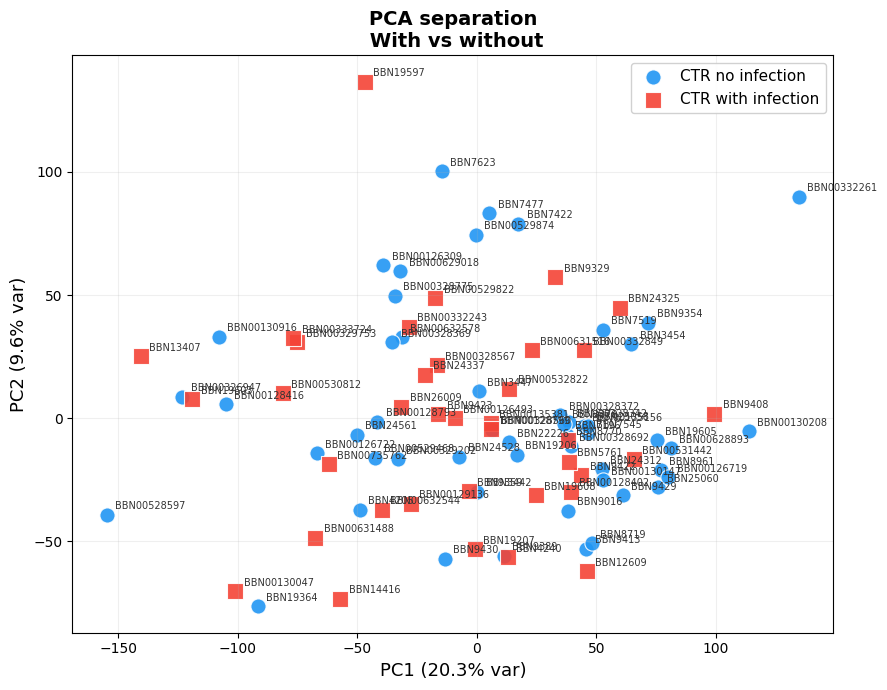

Variance explained: PC1=20.3%, PC2=9.6%


In [48]:
X_combined = np.vstack([X_A_scaled, X_B_scaled])
labels_combined = (['CTR no infection'] * len(group_A_valid) +
                   ['CTR with infection'] * len(group_B_valid))
ids_combined = group_A_valid + group_B_valid

pca = PCA(n_components=2, random_state=42)
pca_coords = pca.fit_transform(X_combined)

pca_df = pd.DataFrame({
    'PC1': pca_coords[:, 0],
    'PC2': pca_coords[:, 1],
    'Group': labels_combined,
    'Sample': ids_combined
})

fig, ax = plt.subplots(figsize=(9, 7))

palette = {'CTR no infection': '#2196F3', 'CTR with infection': '#F44336'}
markers = {'CTR no infection': 'o', 'CTR with infection': 's'}

for group, sub in pca_df.groupby('Group'):
    ax.scatter(sub['PC1'], sub['PC2'],
               label=group,
               color=palette[group],
               marker=markers[group],
               s=120, edgecolors='white', linewidths=0.8, alpha=0.9)
    # Etichetta ogni punto con l'ID campione
    for _, row in sub.iterrows():
        ax.annotate(row['Sample'], (row['PC1'], row['PC2']),
                    textcoords='offset points', xytext=(6, 4),
                    fontsize=7, color='#333333')

ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)', fontsize=13)
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)', fontsize=13)
ax.set_title('PCA separation\n With vs without',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=11, framealpha=0.9)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig('fig_PCA.png', dpi=200)
plt.show()
print(f'Variance explained: PC1={pca.explained_variance_ratio_[0]*100:.1f}%, PC2={pca.explained_variance_ratio_[1]*100:.1f}%')

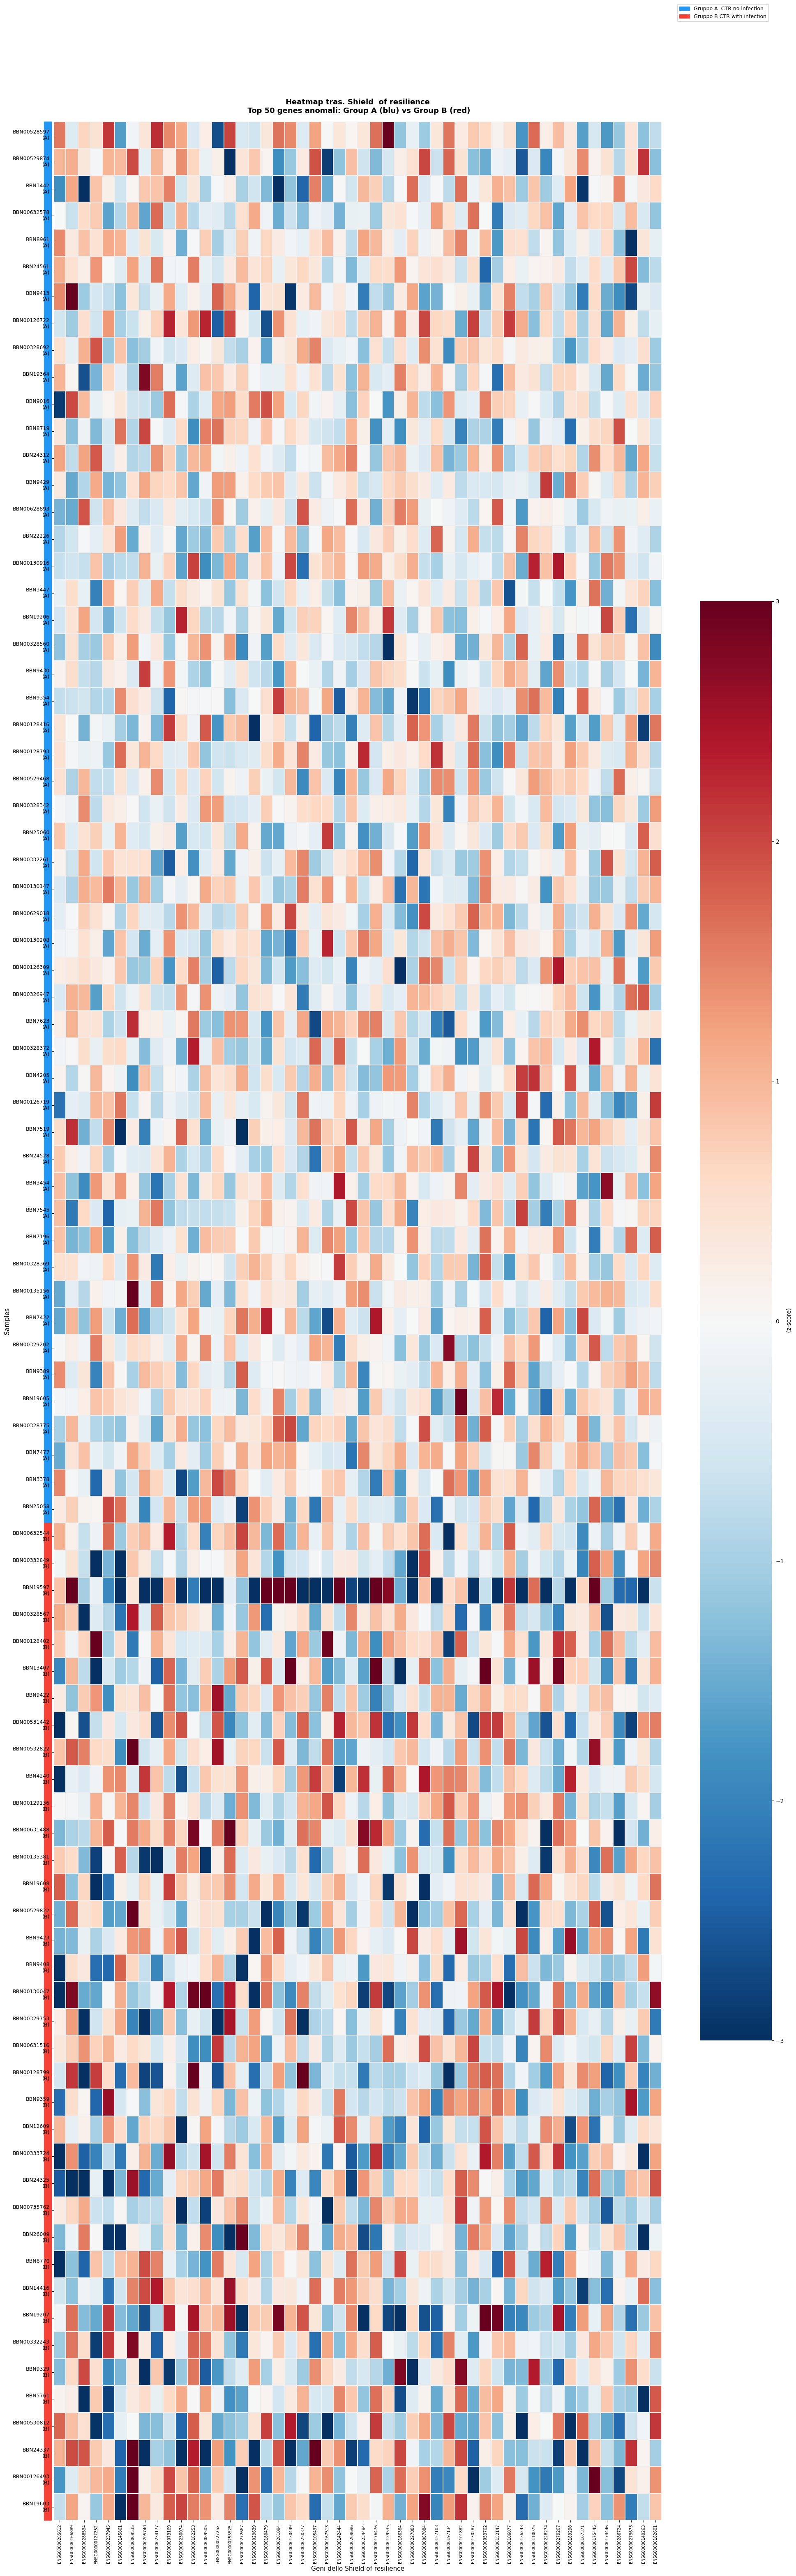

In [49]:
top50_idx = [gene_names.index(g) for g in top_genes_50 if g in gene_names]

heatmap_data = np.vstack([
    X_A_scaled[:, top50_idx],
    X_B_scaled[:, top50_idx]
])

heatmap_df = pd.DataFrame(
    heatmap_data,
    index=(
        [f'{s}\n(A)' for s in group_A_valid] +
        [f'{s}\n(B)' for s in group_B_valid]
    ),
    columns=top_genes_50
)

fig_height = max(6, len(heatmap_df) * 0.7)
fig, ax = plt.subplots(figsize=(min(20, len(top_genes_50) * 0.4 + 4), fig_height))

n_A = len(group_A_valid)
n_B = len(group_B_valid)
row_colors = (['#2196F3'] * n_A + ['#F44336'] * n_B)

sns.heatmap(
    heatmap_df,
    cmap='RdBu_r',
    center=0,
    vmin=-3, vmax=3,
    ax=ax,
    xticklabels=True,
    yticklabels=True,
    linewidths=0.3,
    linecolor='#eeeeee',
    cbar_kws={'label': ' (z-score)', 'shrink': 0.6}
)

ax.set_title('Heatmap tras. Shield  of resilience\n Top 50 genes anomali: Group A (blu) vs Group B (red)',
             fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Geni dello Shield of resilience', fontsize=11)
ax.set_ylabel('Samples', fontsize=11)
ax.tick_params(axis='x', rotation=90, labelsize=7)
ax.tick_params(axis='y', labelsize=9)

# Barra laterale colorata per indicare il gruppo
for i, color in enumerate(row_colors):
    ax.add_patch(plt.Rectangle(
        (-0.8, i), 0.6, 1,
        color=color, transform=ax.transData, clip_on=False
    ))

patch_A = mpatches.Patch(color='#2196F3', label='Gruppo A  CTR no infection')
patch_B = mpatches.Patch(color='#F44336', label='Gruppo B CTR with infection')
ax.legend(handles=[patch_A, patch_B], loc='upper right',
          bbox_to_anchor=(1.18, 1.05), fontsize=9)

plt.tight_layout()
plt.savefig('fig_heatmap_top50.png', dpi=200, bbox_inches='tight')
plt.show()

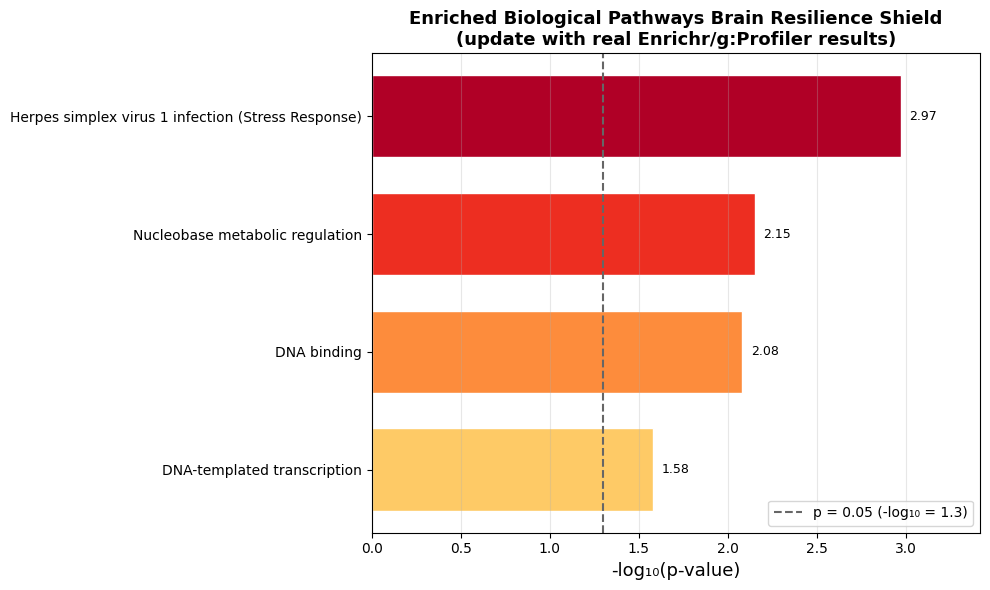

In [50]:
pathway_df = pd.DataFrame({
    'Pathway': list(pathway_results.keys()),
    'neg_log10_p': list(pathway_results.values())
}).sort_values('neg_log10_p')

fig, ax = plt.subplots(figsize=(10, 6))

colors = plt.cm.YlOrRd(np.linspace(0.3, 0.9, len(pathway_df)))
bars = ax.barh(pathway_df['Pathway'], pathway_df['neg_log10_p'],
               color=colors, edgecolor='white', height=0.7)

# Significance threshold (p < 0.05 → -log10 > 1.3)
ax.axvline(x=1.3, color='#666666', linestyle='--', lw=1.5,
           label='p = 0.05 (-log₁₀ = 1.3)')

# Values on bars
for bar, val in zip(bars, pathway_df['neg_log10_p']):
    ax.text(val + 0.05, bar.get_y() + bar.get_height()/2,
            f'{val:.2f}', va='center', ha='left', fontsize=9)

ax.set_xlabel('-log₁₀(p-value)', fontsize=13)
ax.set_title('Enriched Biological Pathways Brain Resilience Shield\n'
             '(update with real Enrichr/g:Profiler results)',
             fontsize=13, fontweight='bold')

ax.legend(fontsize=10)
ax.set_xlim(0, max(pathway_df['neg_log10_p']) * 1.15)
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('fig_pathway_enrichment.png', dpi=200)
plt.show()

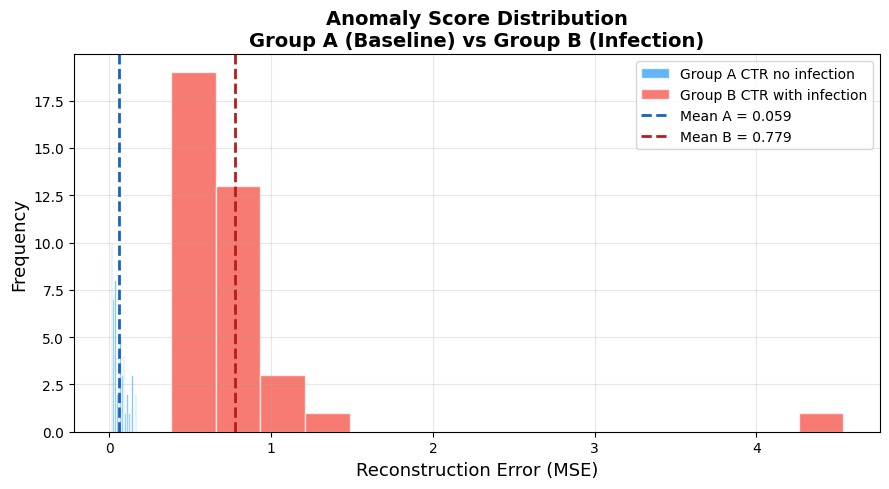

In [51]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(rec_error_A, bins=15, color='#2196F3', alpha=0.7,
        label='Group A CTR no infection', edgecolor='white')
ax.hist(rec_error_B, bins=15, color='#F44336', alpha=0.7,
        label='Group B CTR with infection', edgecolor='white')

ax.axvline(rec_error_A.mean(), color='#1565C0', lw=2, ls='--',
           label=f'Mean A = {rec_error_A.mean():.3f}')
ax.axvline(rec_error_B.mean(), color='#B71C1C', lw=2, ls='--',
           label=f'Mean B = {rec_error_B.mean():.3f}')

ax.set_xlabel('Reconstruction Error (MSE)', fontsize=13)
ax.set_ylabel('Frequency', fontsize=13)
ax.set_title('Anomaly Score Distribution\nGroup A (Baseline) vs Group B (Infection)',
             fontsize=14, fontweight='bold')

ax.legend(fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('fig_anomaly_score_distribution.png', dpi=200)
plt.show()